# Video 9: What only Xenium can show us

Notes for this notebook.

COMET gives us sixteen protein markers. Xenium gives us five thousand and one genes. Here we look at liver metabolic genes with no COMET protein equivalent at all, comparing the tumor core against the non tumor liver core.

This notebook reuses the quantification tables from Video 3 and Video 5. All output images are saved into outputs/video9.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline


In [2]:
from pathlib import Path

OUTPUT_DIR = Path("outputs/video9")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder ready at:", OUTPUT_DIR.resolve())


Output folder ready at: C:\Users\m6sbhatt\Documents\Personal\python_projects\unumlocalia\outputs\video9


## Load both cores

We reuse the tumor core table from Video 3 and the non tumor core table from Video 5, since this episode compares liver metabolic genes across both.


In [3]:
df_tumor = pd.read_csv("outputs/video3/core01_hcc_quantification.csv")
df_normal = pd.read_csv("outputs/video5/core02_non_tumour_quantification.csv")

print("Tumor core cells:", len(df_tumor))
print("Non tumor core cells:", len(df_normal))


Tumor core cells: 8283
Non tumor core cells: 5583


## Liver metabolic zonation genes

Healthy liver tissue is organized into repeating functional units, with different metabolic genes active depending on how close a cell sits to a portal tract versus a central vein. None of the sixteen COMET markers in this panel can show this, it requires gene level resolution across specific candidate genes, exactly what Xenium provides. We use two pericentral genes, CYP1A2 and SLC1A2, and two periportal genes, ARG1 and PCK1, all four of which are present in this gene panel.


In [4]:
zonation_genes = ["CYP1A2", "SLC1A2", "ARG1", "PCK1"]
print("All present in tumor core:", all(g in df_tumor.columns for g in zonation_genes))
print("All present in non tumor core:", all(g in df_normal.columns for g in zonation_genes))


All present in tumor core: True
All present in non tumor core: True


These tissue microarray cores are small, roughly one to two millimeters across, which does not usually span enough tissue to capture a full portal to central gradient within a single core. Rather than look for a spatial gradient here, we compare overall detection levels for these four genes between the tumor and non tumor cores.


In [5]:
print("Total transcript counts and detection rate, tumor core:")
for gene in zonation_genes:
    total = df_tumor[gene].sum()
    nonzero = (df_tumor[gene] > 0).sum()
    print(f"{gene}: total = {total}, nonzero cells = {nonzero} of {len(df_tumor)} ({100 * nonzero / len(df_tumor):.1f} percent)")

print("\nTotal transcript counts and detection rate, non tumor core:")
for gene in zonation_genes:
    total = df_normal[gene].sum()
    nonzero = (df_normal[gene] > 0).sum()
    print(f"{gene}: total = {total}, nonzero cells = {nonzero} of {len(df_normal)} ({100 * nonzero / len(df_normal):.1f} percent)")


Total transcript counts and detection rate, tumor core:
CYP1A2: total = 74, nonzero cells = 70 of 8283 (0.8 percent)
SLC1A2: total = 70, nonzero cells = 61 of 8283 (0.7 percent)
ARG1: total = 1799, nonzero cells = 919 of 8283 (11.1 percent)
PCK1: total = 134, nonzero cells = 122 of 8283 (1.5 percent)

Total transcript counts and detection rate, non tumor core:
CYP1A2: total = 1868.0, nonzero cells = 843 of 5583 (15.1 percent)
SLC1A2: total = 391.0, nonzero cells = 317 of 5583 (5.7 percent)
ARG1: total = 5203.0, nonzero cells = 2257 of 5583 (40.4 percent)
PCK1: total = 2090.0, nonzero cells = 1327 of 5583 (23.8 percent)


## Metabolic gene silencing in tumor tissue

Every one of these four genes is detected far more in the non tumor core than in the tumor core, not a subtle shift, a large one. This is a well documented feature of hepatocellular carcinoma, tumor hepatocytes broadly shut down the genes responsible for normal liver metabolic function, sometimes called physiological dedifferentiation, distinct from the structural, architectural changes visible on H and E.

CYP1A2 in particular is described in the literature as typically silenced in HCC tumor tissue. ARG1 has been separately reported as significantly downregulated in HCC. PCK1 is part of a broader, well documented suppression of gluconeogenesis in tumor hepatocytes. None of these genes have a corresponding protein on our COMET panel, this is biology only the much larger Xenium gene panel can show us.


In [6]:
mean_per_cell_tumor = df_tumor[zonation_genes].sum() / len(df_tumor)
mean_per_cell_normal = df_normal[zonation_genes].sum() / len(df_normal)

comparison = pd.DataFrame({
    "tumor_mean_per_cell": mean_per_cell_tumor,
    "non_tumor_mean_per_cell": mean_per_cell_normal,
})
comparison["fold_change_non_tumor_over_tumor"] = (
    comparison["non_tumor_mean_per_cell"] / comparison["tumor_mean_per_cell"]
)
print(comparison.round(3))


        tumor_mean_per_cell  non_tumor_mean_per_cell  \
CYP1A2                0.009                    0.335   
SLC1A2                0.008                    0.070   
ARG1                  0.217                    0.932   
PCK1                  0.016                    0.374   

        fold_change_non_tumor_over_tumor  
CYP1A2                            37.451  
SLC1A2                             8.287  
ARG1                               4.291  
PCK1                              23.140  


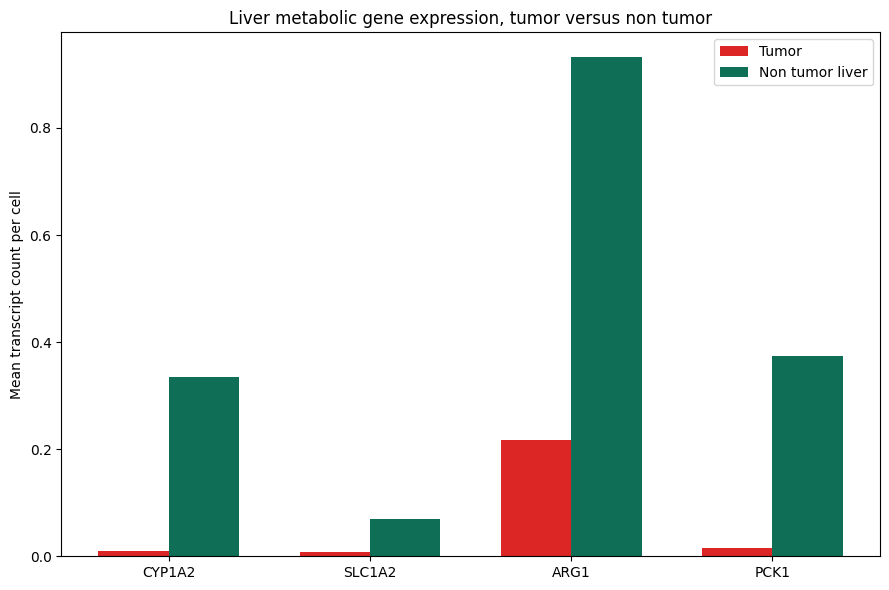

Saved slide_metabolic_genes_tumor_vs_normal.png


In [7]:
fig, ax = plt.subplots(figsize=(9, 6))

x = np.arange(len(zonation_genes))
width = 0.35

ax.bar(x - width / 2, comparison["tumor_mean_per_cell"], width, label="Tumor", color="#DC2626")
ax.bar(x + width / 2, comparison["non_tumor_mean_per_cell"], width, label="Non tumor liver", color="#0F6E56")

ax.set_xticks(x)
ax.set_xticklabels(zonation_genes)
ax.set_ylabel("Mean transcript count per cell")
ax.set_title("Liver metabolic gene expression, tumor versus non tumor")
ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_metabolic_genes_tumor_vs_normal.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_metabolic_genes_tumor_vs_normal.png")


## Summary

Liver metabolic genes with no COMET protein equivalent show a clear, well supported pattern, broad silencing in tumor tissue compared to non tumor liver, consistent with published HCC biology. This is a genuine example of biology that only Xenium's much larger gene panel can reveal.

Next episode, we compare protein and transcript together systematically, checking every matched marker and gene pair in this dataset, not just the ones that happen to agree.
